# Vistas minables

A partir de los datos limpios, guardamos dos tablas en `data/vistas/`. Ejecutar las celdas desde `mineria/` con el `config.py` de esa carpeta.

In [20]:
from config import conectar, ruta_sql

con = conectar()

# Ejecuta una consulta SQL y devuelve el resultado como DataFrame.
def q(consulta):
    return con.sql(consulta).df()

## 1. Leer los archivos limpios y contar los oyentes por artista

In [21]:
con.execute(f"CREATE OR REPLACE VIEW events_clean AS SELECT * FROM {ruta_sql('events_clean')}")
con.execute(f"CREATE OR REPLACE VIEW acoustic_clean AS SELECT * FROM {ruta_sql('acoustic_clean')}")
con.execute(f"CREATE OR REPLACE VIEW users_clean AS SELECT * FROM {ruta_sql('users_clean')}")

# Cantidad de usuarios distintos que escucharon a cada artista
con.execute("""
    CREATE OR REPLACE TEMP TABLE oyentes_artista AS
    SELECT artist_id, COUNT(DISTINCT user_id) AS oyentes
    FROM events_clean
    GROUP BY artist_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 2. Una fila por usuario

In [22]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE resumen_audio AS
    SELECT e.user_id,
           COUNT(*)                AS escuchas_con_audio,
           AVG(a.energy)           AS energy_media,
           STDDEV(a.energy)        AS energy_std,
           AVG(a.valence)          AS valence_media,
           STDDEV(a.valence)       AS valence_std,
           AVG(a.danceability)     AS dance_media,
           AVG(a.acousticness)     AS acoustic_media,
           AVG(a.instrumentalness) AS instrumental_media,
           AVG(a.tempo)            AS tempo_medio,
           AVG(a.speechiness)      AS speechiness_media,
           AVG(a.loudness)         AS loudness_media
    FROM events_clean e
    JOIN acoustic_clean a ON e.track_id = a.track_id
    GROUP BY e.user_id
    -- Pedimos al menos 100 escuchas de canciones con datos de audio.
    HAVING COUNT(*) >= 100
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [23]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE por_artista AS
    -- Una fila por usuario y artista. Si lo escuchó ocho veces, n vale 8.
    SELECT user_id, artist_id, COUNT(*) AS n
    FROM events_clean
    GROUP BY user_id, artist_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [24]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE artista_top AS
    -- El mayor conteo corresponde al artista más escuchado por ese usuario.
    SELECT user_id, MAX(n) AS escuchas_top
    FROM por_artista
    GROUP BY user_id
""")

In [25]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE resumen_consumo AS
    SELECT e.user_id,
           COUNT(*)                    AS total_escuchas,
           COUNT(DISTINCT e.artist_id) AS artistas_distintos,
           -- Cada escucha aporta el logaritmo de la cantidad de oyentes del artista.
           AVG(LOG10(o.oyentes))       AS popularidad_media
    FROM events_clean e
    LEFT JOIN oyentes_artista o ON e.artist_id = o.artist_id
    GROUP BY e.user_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [26]:
consulta_usuarios = """
SELECT c.user_id,
       c.total_escuchas,
       c.artistas_distintos,
       a.escuchas_con_audio,
       -- Parte del total de escuchas que tiene datos de audio.
       a.escuchas_con_audio * 1.0 / c.total_escuchas
           AS pct_escuchas_con_audio,
       a.energy_media,
       a.energy_std,
       a.valence_media,
       a.valence_std,
       a.dance_media,
       a.acoustic_media,
       a.instrumental_media,
       a.tempo_medio,
       a.speechiness_media,
       a.loudness_media,
       c.popularidad_media,
       -- 0.25 significa que una de cada cuatro escuchas fue de su artista favorito.
       t.escuchas_top * 1.0 / c.total_escuchas
           AS pct_artista_top,
       -- Usamos estos datos para describir los grupos.
       u.country,
       u.age,
       u.gender
FROM resumen_audio a
JOIN resumen_consumo c ON a.user_id = c.user_id
JOIN artista_top t ON a.user_id = t.user_id
LEFT JOIN users_clean u ON a.user_id = u.user_id
"""

con.execute(f"""
    COPY ({consulta_usuarios})
    TO {ruta_sql('vista_usuarios')} (FORMAT parquet)
""")

### Cómo quedó la vista de usuarios

In [27]:
vista_usuarios = q(f"SELECT * FROM {ruta_sql('vista_usuarios')} ORDER BY user_id")
print(f"Vista de usuarios: {len(vista_usuarios):,} filas y {len(vista_usuarios.columns)} columnas")
display(vista_usuarios.head(10))

Vista de usuarios: 53,289 filas y 20 columnas


,user_id,total_escuchas,artistas_distintos,escuchas_con_audio,pct_escuchas_con_audio,energy_media,energy_std,valence_media,valence_std,dance_media,acoustic_media,instrumental_media,tempo_medio,speechiness_media,loudness_media,popularidad_media,pct_artista_top,country,age,gender
0,384,10856,234,10856,1.0,0.692481,0.266291,0.255559,0.192077,0.371849,0.157200,0.321951,125.324055,0.069465,-8.605247,2.961045,0.059967,GB,35,m
1,3653,7699,836,7699,1.0,0.692654,0.247280,0.423251,0.251472,0.462766,0.202390,0.414605,125.802663,0.095818,-9.083681,2.967090,0.023120,GB,31,m
2,4813,409,140,409,1.0,0.486096,0.240729,0.431153,0.262319,0.515086,0.412242,0.422693,119.262931,0.073291,-11.816682,2.598653,0.068460,US,43,m
3,5069,10333,1285,10333,1.0,0.672954,0.225716,0.429171,0.257580,0.562328,0.216448,0.436180,123.047989,0.079066,-8.917415,3.397394,0.025259,AT,30,m
4,5213,182,35,182,1.0,0.462430,0.266051,0.287463,0.248646,0.472010,0.450140,0.685044,114.624352,0.061505,-15.025929,2.711766,0.126374,GB,37,no informado
5,5834,9886,844,9886,1.0,0.581626,0.232563,0.432997,0.250698,0.551725,0.340894,0.258334,126.228633,0.062054,-10.017196,3.019325,0.108234,DE,<NA>,no informado
6,6958,9422,1095,9422,1.0,0.524074,0.238465,0.423214,0.255581,0.576040,0.342471,0.402906,119.475999,0.052720,-11.319382,3.151546,0.022501,US,36,m
7,7687,665,94,665,1.0,0.685825,0.191182,0.499571,0.234228,0.552992,0.228310,0.117595,116.599335,0.096172,-7.455767,2.988783,0.094737,IE,<NA>,m
8,11297,8836,1628,8836,1.0,0.644894,0.253404,0.439607,0.244482,0.531921,0.267601,0.231633,122.266733,0.101246,-8.707441,3.154515,0.043006,DE,31,no informado
9,14308,10409,531,10409,1.0,0.633961,0.230538,0.512667,0.244569,0.521133,0.279056,0.118914,125.965246,0.045858,-7.734831,3.187506,0.041599,BR,31,m


In [28]:
# Contamos los datos faltantes en cada columna y resumimos las variables numéricas.
display(vista_usuarios.isna().sum().to_frame("valores_faltantes"))
display(vista_usuarios.describe().T.round(3))

,valores_faltantes
user_id,0
total_escuchas,0
artistas_distintos,0
escuchas_con_audio,0
pct_escuchas_con_audio,0
energy_media,0
energy_std,0
valence_media,0
valence_std,0
dance_media,0


,count,mean,std,min,25%,50%,75%,max
user_id,53289.0,23144265.899623,16094451.221663,384.0,8065274.0,19857764.0,38124557.0,50900118.0
total_escuchas,53289.0,6580.227345,9081.736118,100.0,1534.0,5310.0,8865.0,345014.0
artistas_distintos,53289.0,337.370058,366.793969,1.0,113.0,229.0,434.0,13354.0
escuchas_con_audio,53289.0,6580.227345,9081.736118,100.0,1534.0,5310.0,8865.0,345014.0
pct_escuchas_con_audio,53289.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
energy_media,53289.0,0.692687,0.117028,0.102642,0.615357,0.694493,0.778673,0.964863
energy_std,53289.0,0.213505,0.039268,0.010329,0.188542,0.218539,0.241184,0.406878
valence_media,53289.0,0.424335,0.097475,0.043585,0.361969,0.429971,0.489383,0.844944
valence_std,53289.0,0.230226,0.027479,0.045913,0.215965,0.23517,0.24894,0.364258
dance_media,53289.0,0.495884,0.0791,0.103918,0.444998,0.499692,0.548037,0.861681


### 2.1. Correlación entre variables

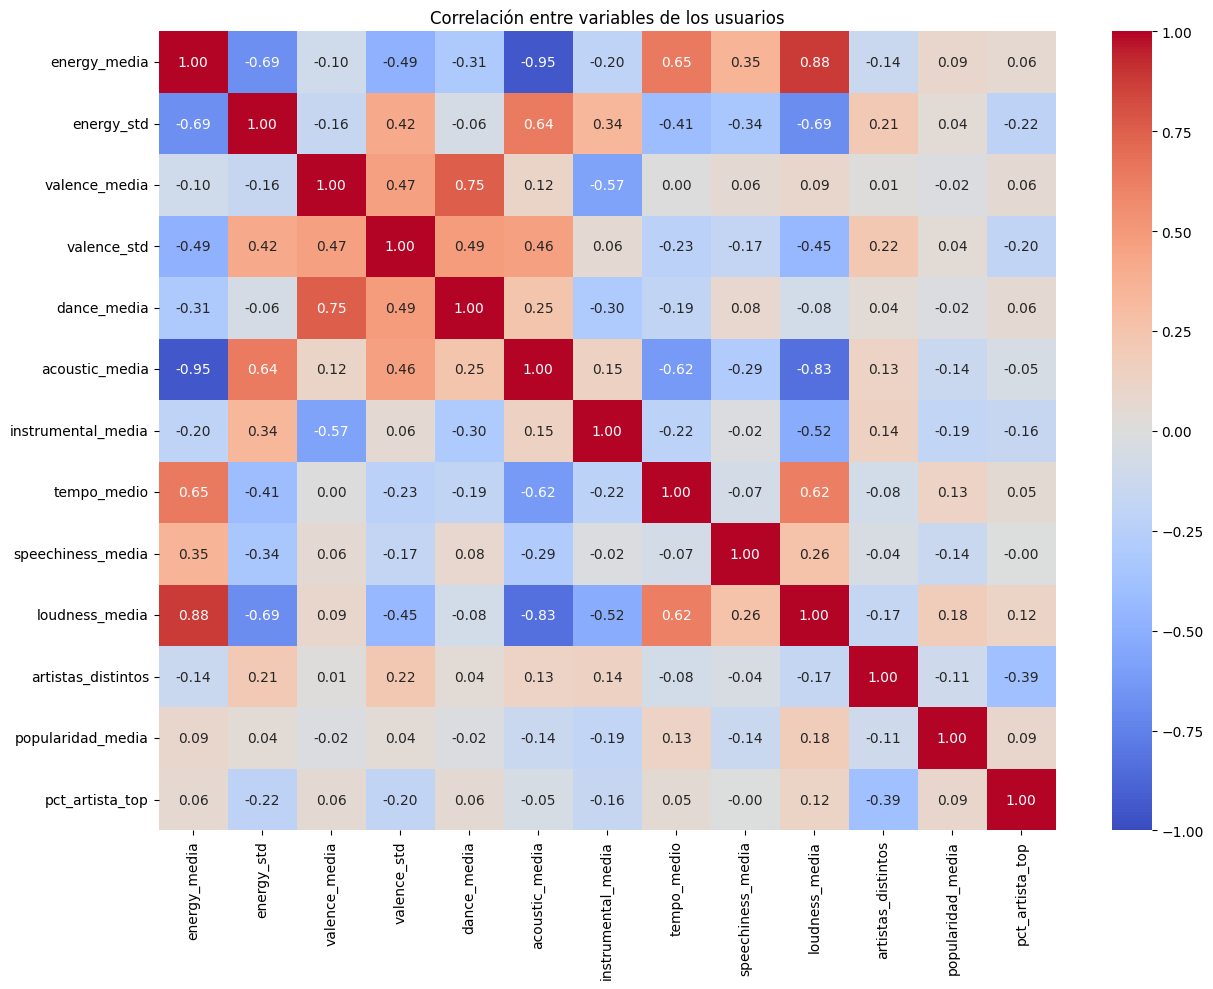

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionamos las posibles variables para el clustering
variables_clustering = [
    "energy_media",
    "energy_std",
    "valence_media",
    "valence_std",
    "dance_media",
    "acoustic_media",
    "instrumental_media",
    "tempo_medio",
    "speechiness_media",
    "loudness_media",
    "artistas_distintos",
    "popularidad_media",
    "pct_artista_top"
]

# Calculamos la matriz de correlación de Pearson
corr = vista_usuarios[variables_clustering].corr()

# Graficamos la matriz de correlación
plt.figure(figsize=(13, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlación entre variables de los usuarios")
plt.tight_layout()
plt.show()

### 2.2. Variables con mayor correlación

In [30]:
# Mostramos los pares de variables con una correlación
# mayor o igual a 0.7 en valor absoluto

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        valor = corr.iloc[i, j]

        if abs(valor) >= 0.7:
            print(f"{corr.columns[i]} - {corr.columns[j]}: {valor:.3f}")

energy_media - acoustic_media: -0.951
energy_media - loudness_media: 0.879
valence_media - dance_media: 0.750
acoustic_media - loudness_media: -0.834


### 2.3. Relación entre cantidad de escuchas y artistas distintos

In [31]:
vista_usuarios[["total_escuchas", "artistas_distintos"]].corr()

,total_escuchas,artistas_distintos
total_escuchas,1.000000,0.465953
artistas_distintos,0.465953,1.000000


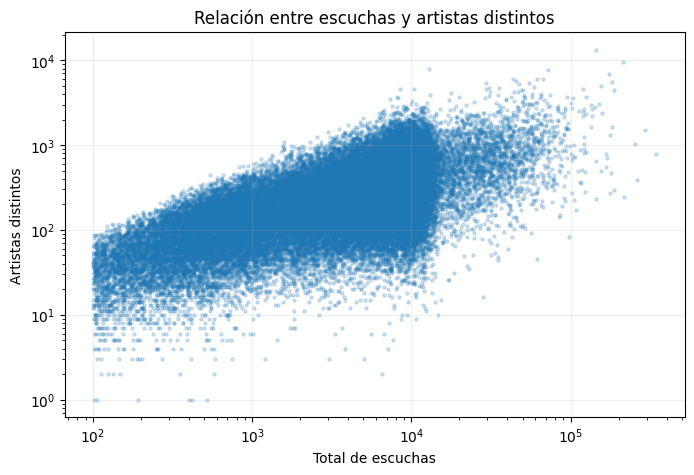

In [32]:
plt.figure(figsize=(8, 5))

plt.scatter(
    vista_usuarios["total_escuchas"],
    vista_usuarios["artistas_distintos"],
    alpha=0.2,
    s=5
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Total de escuchas")
plt.ylabel("Artistas distintos")
plt.title("Relación entre escuchas y artistas distintos")
plt.grid(alpha=0.2)
plt.show()

In [33]:
vista_usuarios[["total_escuchas", "artistas_distintos"]].corr(
    method="spearman"
)

,total_escuchas,artistas_distintos
total_escuchas,1.000000,0.609677
artistas_distintos,0.609677,1.000000


## 3. Una fila por usuario y artista

In [39]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE top_artistas AS
    -- Para esta vista elegimos 5.000 artistas de todo el historial.
    SELECT artist_id
    FROM oyentes_artista
    ORDER BY oyentes DESC, artist_id
    LIMIT 5000
""")

In [35]:
# Reutilizamos el conteo anterior. El JOIN conserva los artistas del catálogo elegido.
con.execute(f"""
    COPY (
        SELECT p.user_id, p.artist_id, p.n AS escuchas
        FROM por_artista p
        JOIN top_artistas t ON p.artist_id = t.artist_id
    ) TO {ruta_sql('vista_usuario_artista')} (FORMAT parquet)
""")

### Vista usuario–artista

In [36]:
# Leemos diez filas del archivo guardado. Cada fila corresponde a un par distinto.
display(q(f"""
    SELECT user_id, artist_id, escuchas
    FROM {ruta_sql('vista_usuario_artista')}
    ORDER BY user_id, escuchas DESC, artist_id
    LIMIT 10
"""))

,user_id,artist_id,escuchas
0,384,67,651
1,384,17352,458
2,384,2583,384
3,384,15202,362
4,384,9037,348
5,384,7993,320
6,384,1996,299
7,384,47,294
8,384,362,241
9,384,8450,219


### Cuántas escuchas quedan y qué tan llena está la matriz

In [41]:
resumen = q(f"""
    SELECT COUNT(*) AS pares,
           COUNT(DISTINCT user_id) AS usuarios,
           COUNT(DISTINCT artist_id) AS artistas,
           SUM(escuchas) AS escuchas,
           MEDIAN(escuchas) AS mediana_por_par,
           MAX(escuchas) AS maximo_por_par
    FROM {ruta_sql('vista_usuario_artista')}
""")
display(resumen)

totales = q("""
    SELECT COUNT(*) AS escuchas, COUNT(DISTINCT user_id) AS usuarios
    FROM events_clean
""")
vista = resumen.iloc[0]
total = totales.iloc[0]

print(f"Escuchas conservadas: {100 * vista.escuchas / total.escuchas:.0f}%")
print(f"Usuarios conservados: {100 * vista.usuarios / total.usuarios:.0f}%")
# Comparamos los pares observados con todas las combinaciones posibles.
pares_posibles = vista.usuarios * vista.artistas
print(f"Densidad de la matriz: {100 * vista.pares / pares_posibles:.0f}%")

,pares,usuarios,artistas,escuchas,mediana_por_par,maximo_por_par
0,10370590,55001,5000,256459288.0,4.0,181440


Escuchas conservadas: 73%
Usuarios conservados: 100%
Densidad de la matriz: 4%


### Distribución de las escuchas por par

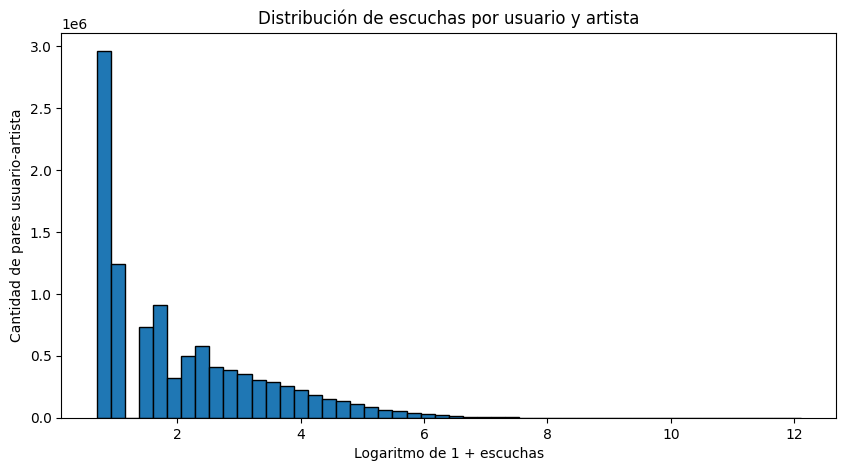

In [38]:
import numpy as np

# Contamos cuántos pares tienen la misma cantidad de escuchas.
frecuencias = q(f"""
    SELECT escuchas, COUNT(*) AS pares
    FROM {ruta_sql('vista_usuario_artista')}
    GROUP BY escuchas
    ORDER BY escuchas
""")

plt.figure(figsize=(10, 5))
plt.hist(np.log1p(frecuencias["escuchas"]), weights=frecuencias["pares"], bins=50, edgecolor="black")
plt.xlabel("Logaritmo de 1 + escuchas")
plt.ylabel("Cantidad de pares usuario-artista")
plt.title("Distribución de escuchas por usuario y artista")
plt.show()